<a href="https://colab.research.google.com/github/studiousdoston/computer_vision/blob/main/menu_detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("Menu Detector!")

Menu Detector!


In [ ]:
# Import Libraries
from google.colab import drive

import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim

from PIL import Image, UnidentifiedImageError
import os
import numpy as np



In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Define Dataset Path

DATASET_PATH = '/content/drive/MyDrive/food101_dataset'
print("DATASET_PATH:", DATASET_PATH)


CUSTOM_CLASS_MAPPING = {
    "kebab": "kebab",
    "hot_dog" : "hot_dog",
    "baklava": "dessert",     # label grouping | class consoldation
    "cheesecake ": "dessert", # label grouping | class consoldation
    "pilaf": "pilaf",
    "pizza": "pizza",
    "bibimbap": "bibimbap",
}

CLASSES = ["pizza", "bibimbap", "hot_dog", "dessert", "kebab", "pilaf"]
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

print(NUM_CLASSES)
print(CLASS_TO_IDX)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.299, 0.224, 0.225])
])

# 0~255
# 0.0~1.0
# H, W, C => C, H, W | RGB
# pixel = (pixel - mean) / std

DATASET_PATH: /content/drive/MyDrive/food101_dataset
6
{'pizza': 0, 'bibimbap': 1, 'hot_dog': 2, 'dessert': 3, 'kebab': 4, 'pilaf': 5}


# Custom Dataset Class

In [ ]:
from PIL.Image import UnidentifiedImageError
class FoodDataset(Dataset):
  def __init__(self, images, labels, transform=None):
    self.images = images
    self.labels = labels
    self.transform = transform

  def __len__(self):
    # print("images_length", len(self.images))
    return len(self.images)

  def __getitem__(self, idx):
    img_path = self.images[idx]
    # print("images_path", img_path)
    label = self.labels[idx]
    # print("label", label)
    try:
      image = Image.open(img_path)
      if image.mode == "P" or image.mode == "RGBA":
        image = image.convert("RGBA").convert("RGB")
      else:
        image = image.convert("RGB")
    except (UnidentifiedImageError, OSError):
      print(f"Skipping borken image: {img_path}")
      return self.__getitem__((idx+1) % len(self.images))
    if self.transform:
      image = self.transform(image)
    return image, label

# Gather and Split Data

In [ ]:
all_images = []
for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
  class_path = os.path.join(DATASET_PATH, original_class)
  print("class_path \n", class_path)
  if not os.path.exists(class_path):
    print(f"Warning: {class_path} not found")
    continue

  for img in os.listdir(class_path):
    if img.endswith(('.jpg', 'jpeg', '.png')):
      full_path = os.path.join(class_path, img)
      all_images.append((full_path, CLASS_TO_IDX[mapped_class]))

np.random.shuffle(all_images)
split = int(0.8 * len(all_images))
train_data = all_images[:split]
val_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*val_data)

#print("all_images", all_images)

dataset = FoodDataset(train_images, train_labels)
print(len(dataset))
img, lbl = dataset[0]

class_path 
 /content/drive/MyDrive/food101_dataset/kebab
class_path 
 /content/drive/MyDrive/food101_dataset/hot_dog
class_path 
 /content/drive/MyDrive/food101_dataset/baklava
class_path 
 /content/drive/MyDrive/food101_dataset/cheesecake 
class_path 
 /content/drive/MyDrive/food101_dataset/pilaf
class_path 
 /content/drive/MyDrive/food101_dataset/pizza
class_path 
 /content/drive/MyDrive/food101_dataset/bibimbap
3372


In [ ]:
train_dataset = FoodDataset(train_images, train_labels, transform=transform)
val_dataset = FoodDataset(val_images, val_labels, transform=transform)

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)


print("\n\ntrain_loader", len(train_loader))
print("val_loader", len(val_loader))



train_loader 106
val_loader 27


# Pretrained Model

In [ ]:
model = mobilenet_v2(weights="IMAGENET1K_V1")
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 134MB/s]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device
model = model.to(device)
print(device)

cuda


## Loss Function & Optimizer & Benchmark

In [ ]:
criterion = nn.CrossEntropyLoss() # Loss Function
optimizer = optim.Adam(model.parameters(), lr=0.001)
torch.backends.cudnn.benchmark=True # Benchmark setting

print("criterion", criterion)
print("optimizer", optimizer)

criterion CrossEntropyLoss()
optimizer Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## Traininig loop

In [ ]:
epochs = 10
best_accuracy = 0.0

for epoch in range(epochs):
    ### Training
    model.train()
    running_loss = 0.0 # 70% acc | 30% loss

    for images, labels in train_loader: # Forward and Backward(Backpropagation)
        images, labels = images.to(device), labels.to(device)
        # zero_grad()
        optimizer.zero_grad() # zero the gradient
        outputs = model(images) # Forward pass Dog | 5 Classes
        loss = criterion(outputs, labels) # calculate loss
        loss.backward() # back propogation
        optimizer.step() # optimization
        running_loss += loss.item() # Track loss

    # Validation
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_acc = 100 * correct / total # Calculate Validation Accuracy
    print(f"Epoch [{epoch+1}/{epochs} Loss: {running_loss/len(train_loader): .4f}, Val Accuracy: {val_acc:.2f}%]")

    if val_acc > best_accuracy:
        best_accuracy = val_acc
        torch.save(model.state_dict(), '/content/menu_detector.pth')
        print("↳ Saved new best model!")


Epoch [1/10 Loss:  0.5152, Val Accuracy: 87.68%]
↳ Saved new best model!
Epoch [2/10 Loss:  0.2516, Val Accuracy: 86.73%]
Epoch [3/10 Loss:  0.2076, Val Accuracy: 87.20%]
Epoch [4/10 Loss:  0.2240, Val Accuracy: 88.86%]
↳ Saved new best model!
Epoch [5/10 Loss:  0.1619, Val Accuracy: 90.17%]
↳ Saved new best model!
Epoch [6/10 Loss:  0.1458, Val Accuracy: 87.80%]
Epoch [7/10 Loss:  0.1150, Val Accuracy: 91.23%]
↳ Saved new best model!
Epoch [8/10 Loss:  0.1076, Val Accuracy: 91.23%]
Epoch [9/10 Loss:  0.0677, Val Accuracy: 92.89%]
↳ Saved new best model!
Epoch [10/10 Loss:  0.1074, Val Accuracy: 90.05%]


# Menu Detector model usage

device cuda
Upload one or more images of hamburger or hot dog:


Saving pilaf_094.jpg to pilaf_094.jpg


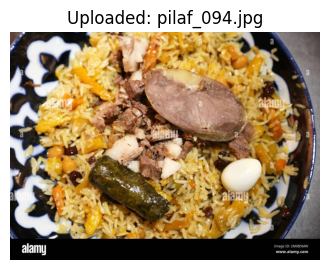

Prediction:
 ✅pilaf:  99.74%
 ✅bibimbap:  0.22%
 ✅kebab:  0.03%
 ✅pizza:  0.01%


In [ ]:
### Required Imports
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt

###  Define Semantic Classes
CLASSES = ["pizza", "bibimbap", "hot_dog", "dessert", "kebab", "pilaf"]
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}

### Transform for uploaded images (no-augmentations!)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.299, 0.224, 0.225])
])

### Load Model
model = mobilenet_v2(weights=None)
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(torch.load("/content/menu_detector.pth", map_location="cpu"))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device", device)
model = model.to(device)
model.eval()

### Upload & Predict
print("Upload one or more images of hamburger or hot dog:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = Image.open(io.BytesIO(uploaded[image_name])).convert("RGB")

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Uploaded: {image_name}")
    plt.show()

    # Predict
    image_tensor = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)[0]
        topk = torch.topk(probs, 4)

    print("Prediction:")
    for i in range(topk.indices.size(0)):
        label = CLASSES[topk.indices[i]]
        confidence = topk.values[i].item()*100
        print(f" ✅{label}: {confidence: .2f}%")
